In [137]:
import numpy as np
import pandas as pd
from matplotlib import pyplot
print(np.__version__)
#from sklearn.metrics import ConfusionMatrixDisplay
#import seaborn

import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')

import multi_fgl_utils as util
import plot_util as putil
import dio3

1.26.4


In [138]:
if 1:
    import importlib
    importlib.reload(util);


In [139]:
def get_descr_str(llat_ROI, hlat_ROI, cdict={}, bmask=10):
    res = cdict.get('case', '4FGL-DR4')
    res += '_%s' % cdict.get('unas_sources', 'unas_unk')
    if llat_ROI:
        res += '_unas_below_b%i' % bmask
    if hlat_ROI:
        res += '_unas_above_b%i' % bmask
    return res


In [140]:
# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL_DR3'
folder_out = None
if cat_name == '4FGL-DR4':
    baseline_case = '4FGL-DR4_GMM_RF'
    #case1 = '4FGL-DR4_GMM_RF'
    #case1 = '4FGL-DR4_GMM_RF_no_bcu_spp'
    #case1 = '4FGL-DR4_GMM_RF_no_bcu'
    #case1 = '4FGL-DR4_GMM_RF_no_coord'
    #case1 = '4FGL-DR4_GMM_RF_no_coord_no_bcu'
    case1 = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #case2 = '4FGL-DR4_GMM_PDF_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_coord_pshift_nGauss1_npar4'
    #case2 = '4FGL-DR4_GMM_PDF_no_bcu_pshift_nGauss1_npar4'
    #case2 = '4FGL-DR4_GMM_PDF_no_bcu_spp_pshift_nGauss1_npar4'

alg1 = 'RF'
check_prior = 1
if check_prior:
    cat1 = 'Cov'
    cat2 = 'Prior'
    #case2 = '4FGL-DR4_GMM_PDF_pshift_nGauss1_npar4'
    #case2 = '4FGL-DR4_GMM_PDF_no_coord_pshift_nGauss1_npar4'
    #case2 = '4FGL-DR4_GMM_PDF_no_coord_no_bcu_pshift_nGauss1_npar4'
    case2 = '4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4'
    #case2 = '4FGL-DR4_GMM_PDF_no_bcu_pshift_nGauss1_npar4'
    alg2 = 'PDF'
else:
    cat1 = '!bcu'
    cat2 = '!bcu, !coord'
    case2 = '4FGL-DR4_GMM_RF_no_coord_no_bcu'
    alg2 = 'RF'
    

In [141]:
root_folder = '../../'
config_folder = root_folder + 'config/'

# generic inputs
cdict1 = util.get_config_dict(cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=case1, 
                             folder=config_folder)
cdict2 = util.get_config_dict(cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=case2, 
                             folder=config_folder)

cdict1['root_folder'] = root_folder
cdict2['root_folder'] = root_folder

llat = 0
hlat = 0
bmask = 10


In [142]:
save_plots = 0
save_png = 0
descr_str = get_descr_str(llat, hlat, cdict=cdict2, bmask=bmask)
script_fn = 'fermi_multiclass/notebooks/cov_shift/compare_cov_prior_probs.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}

plots_folder = '../../plots/SGU/%s/' % descr_str
if not os.path.isdir(plots_folder):
    print('Make folder')
    os.makedirs(plots_folder)
print(plots_folder)
print(descr_str)

style_folder = '../../data_out/style_dicts/'
style_fn = '%s/style_4class_Gauss.yaml' % (style_folder)
mdl_style_dict = dio3.loaddict(style_fn)
mdl_style_dict['vertical'] = {'color': 'grey', 'ls': (0, (1, 2))}
#for dct in mdl_style_dict.values():
#    dct.pop('ls')

../../plots/SGU/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_unas_unk/
4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_unas_unk


In [143]:
mdl_style_dict

{'000': {'color': '#1f77b4', 'ls': '--'},
 '001': {'color': '#ff7f0e', 'ls': ':'},
 '010': {'color': '#2ca02c', 'ls': (0, (5, 4))},
 '011': {'color': '#d62728', 'ls': (0, (4, 5, 1, 5))},
 'Gauss': {'color': '#9467bd', 'ls': '-.'},
 'assoc': {'color': '#e377c2', 'ls': '-'},
 'model': {'color': '#7f7f7f', 'ls': '--'},
 'unassoc': {'color': 'cornflowerblue', 'ls': (0, (3, 1, 1, 1, 1, 1))},
 'vertical': {'color': 'grey', 'ls': (0, (1, 2))}}

In [144]:
np.sin(np.deg2rad(bmask))

0.17364817766693033

In [145]:
fn = util.get_pcat_fn(cdict1)
summary_fn = fn.replace('prob_cat.csv', 'summary.csv')
print(fn)

cat_df1 = pd.read_csv(fn, index_col=0)
sum_df1 = pd.read_csv(summary_fn, index_col=1, dtype=str)
llat_mask = np.abs(cat_df1['sin(GLAT)']) < np.sin(np.deg2rad(bmask))
umask_tot = (cat_df1[class_name] == 'unas') | (cat_df1[class_name] == 'unk')
n_llat_tot = sum(llat_mask)
n_llat_unas = sum(umask_tot & llat_mask)
print(n_llat_unas, n_llat_tot, 1. *n_llat_unas / n_llat_tot)

fn = util.get_pcat_fn(cdict2)
summary_fn = fn.replace('prob_cat.csv', 'summary.csv')
print(fn)

cat_df2 = pd.read_csv(fn, index_col=0)
sum_df2 = pd.read_csv(summary_fn, index_col=1, dtype=str)

# subselect sources in cat_df1 which are also in cat_df2
cat_df1 = cat_df1.loc[cat_df2.index]
print(len(cat_df1), len(cat_df2))
for cl in sum_df1.index:
    print('%s: %s' %(cl, sum_df1['Physical classes'].loc[cl]))
print(cat_df1.columns)

../../results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_prob_cat.csv
1293 2122 0.6093308199811499
../../results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_unk_prior_shift_npar4_1Gauss_prob_cat.csv
5859 5859
fsrq+: fsrq, nlsy1, css
bll+: bll, sey, sbg, agn, ssrq, rdg
psr+: snr, hmb, nov, pwn, psr, gc
msp+: msp, lmb, glc, gal, sfr, bin
Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1', '1_RF',
       '1_RF_std', '1_NN', '1_NN_std', '2_RF', '2_RF_std', '2_NN', '2_NN_std',
       '3_RF', '3_RF_std', '3_NN', '3_NN_std', '4_RF', '4_RF_std', '4_NN',
       '4_NN_std', 'sample_weight'],
      dtype='object')


In [146]:
#pd.read_csv?

In [147]:
util.get_pcat_fn(cdict1)

'../../results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_prob_cat.csv'

In [148]:
util.get_pcat_fn(cdict1)

'../../results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_prob_cat.csv'

In [149]:
class_name = 'CLASS1'
#mask = (cat_df1[class_name] == 'unas') | (cat_df1[class_name] == 'unk')
#if llat:
#    mask &= np.abs(cat_df1['sin(GLAT)']) < np.sin(np.deg2rad(bmask))
#cat_df1 = cat_df10[mask]

mask = (cat_df2[class_name] == 'unas') | (cat_df2[class_name] == 'unk')
if llat:
    mask &= np.abs(cat_df2['GLAT']) < bmask
#cat_df2 = cat_df20[mask]
sources = cat_df2[mask].index

tree_cat_fn = util.get_tree_cat_fn(cdict2)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
assoc_classes = []
for cls in tree_cat_dict.values():
    assoc_classes.extend(cls)
amask = util.get_cl_mask(assoc_classes, cat_df2, cname=class_name)
if llat:
    amask &= np.abs(cat_df2['GLAT']) < bmask
asources = cat_df2[amask].index

In [150]:
cat_df1

,sin(GLAT),cos(GLON),sin(GLON),log10(Energy_Flux100),log10(Unc_Energy_Flux100),log10(Signif_Avg),LP_index1000MeV,LP_beta,LP_SigCurv,log10(Variability_Index),...,2_NN_std,3_RF,3_RF_std,3_NN,3_NN_std,4_RF,4_RF_std,4_NN,4_NN_std,sample_weight
4FGL J0000.3-7355,-0.678538,0.611651,-0.791128,-11.760649,-12.570003,0.929043,1.984765,0.109999,1.117561,1.108396,...,0.020955,0.000280,0.001444,0.014667,0.006146,0.003521,0.006675,0.019302,0.006429,1.000000
4FGL J0000.5+0743,-0.798945,-0.202043,0.979377,-11.714305,-12.425956,0.754432,2.176364,0.109660,1.194232,1.407714,...,0.045033,0.001405,0.006398,0.012588,0.005605,0.026314,0.024817,0.026918,0.007273,1.000000
4FGL J0000.7+2530,-0.587209,-0.321854,0.946789,-12.094175,-12.607139,0.622967,0.902878,0.251122,1.689082,1.118902,...,0.019215,0.000431,0.002900,0.008059,0.004690,0.020487,0.020286,0.020927,0.009827,1.000000
4FGL J0001.2+4741,-0.247643,-0.410722,0.911761,-11.863557,-12.491841,0.742244,1.997826,0.049796,0.394362,1.461132,...,0.029642,0.000058,0.000264,0.006359,0.002882,0.008068,0.014382,0.005793,0.001835,1.000000
4FGL J0001.2-0747,-0.922572,0.016881,0.999857,-11.107484,-12.288400,1.389117,1.997502,0.037899,1.283201,1.713846,...,0.013401,0.000071,0.000136,0.008861,0.009881,0.000044,0.000093,0.000762,0.000357,0.002515
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4FGL J2359.3+2502,-0.592576,-0.313120,0.949713,-11.877070,-12.505523,0.744970,1.704941,0.135214,1.003298,1.343438,...,0.018069,0.000490,0.002881,0.005621,0.002559,0.003341,0.006509,0.009699,0.003103,1.000000
4FGL J2359.3+1444,-0.722439,-0.251473,0.967864,-11.627869,-12.364560,0.891602,2.708066,0.222978,2.510251,1.132324,...,0.023674,0.042110,0.036244,0.086425,0.038277,0.073483,0.046558,0.234740,0.056068,1.000000
4FGL J2359.7-5041,-0.902380,0.789385,-0.613899,-11.952324,-12.562951,0.711844,2.936976,0.446554,3.037318,0.841006,...,0.018586,0.077604,0.056484,0.245384,0.098062,0.211667,0.063358,0.491506,0.104836,1.000000
4FGL J2359.9-3736,-0.965562,0.968855,-0.247627,-11.756382,-12.551358,1.059774,1.755914,0.185941,2.774415,0.907563,...,0.073933,0.000833,0.004039,0.060356,0.027259,0.059017,0.041044,0.216413,0.064035,1.000000


In [151]:
len(sources), len(asources), n_llat_tot

(2179, 2311, 2122)

In [152]:
(cat_df2)

,log10(Energy_Flux100),LP_beta,log10(LP_EPeak),GLON,GLAT,Signif_Avg,CLASS1,1_PDF,2_PDF,3_PDF,4_PDF,Gauss_PDF
4FGL J0000.3-7355,-11.760649,0.109999,0.030076,307.708984,-42.729538,8.492646,unas,0.168348,0.575888,0.009225,0.119563,0.126976
4FGL J0000.5+0743,-11.714305,0.109660,-0.349232,101.656479,-53.029457,5.681097,unas,0.189166,0.350479,0.010228,0.129620,0.320507
4FGL J0000.7+2530,-12.094175,0.251122,0.948690,108.775070,-35.959175,4.197268,unas,0.029941,0.968732,0.000384,0.000939,0.000004
4FGL J0001.2+4741,-11.863557,0.049796,0.009480,114.250198,-14.338059,5.523873,bcu,0.080707,0.832919,0.002997,0.043842,0.039535
4FGL J0001.2-0747,-11.107484,0.037899,0.014316,89.032722,-67.305008,24.497219,bll,0.073356,0.236130,0.103158,0.071738,0.515618
...,...,...,...,...,...,...,...,...,...,...,...,...
4FGL J2359.3+2502,-11.877070,0.135214,0.473850,108.247383,-36.340054,5.558664,unas,0.115943,0.854659,0.006659,0.018670,0.004069
4FGL J2359.3+1444,-11.627869,0.222978,-0.689550,104.564713,-46.256252,7.791155,unas,0.266414,0.031424,0.007959,0.064871,0.629332
4FGL J2359.7-5041,-11.952324,0.446554,-0.455627,322.128052,-64.472755,5.150436,bcu,0.061082,0.015336,0.003073,0.274645,0.645864
4FGL J2359.9-3736,-11.756382,0.185941,0.285051,345.662842,-74.919624,11.475555,bcu,0.157764,0.661594,0.005711,0.124845,0.050086


In [153]:
sum(cat_df2.loc[sources]['Gauss_PDF']>0.5)

913

fsrq+
bll+
psr+
msp+
Gauss


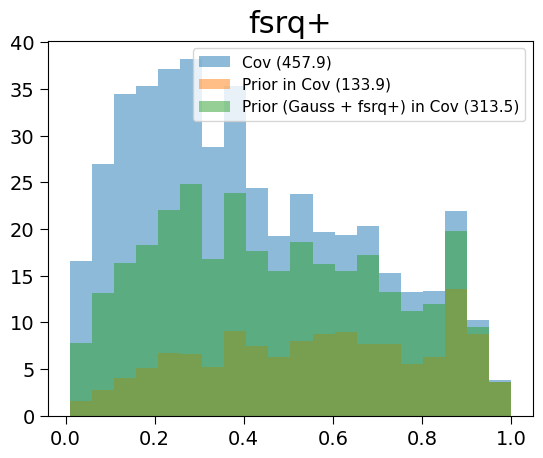

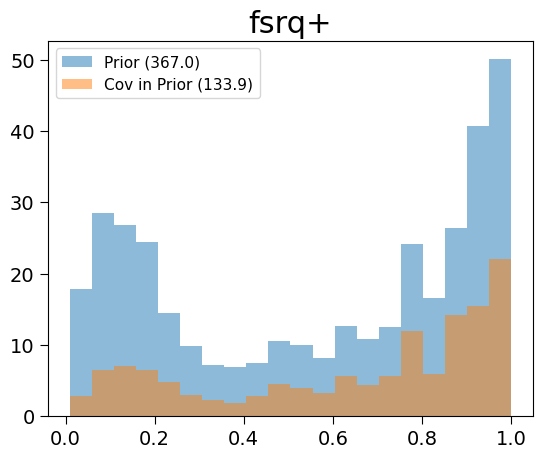

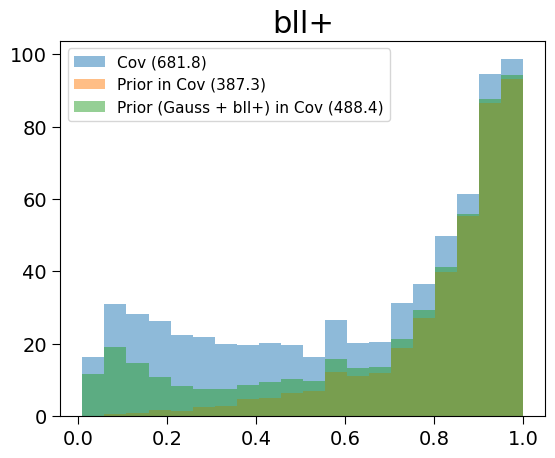

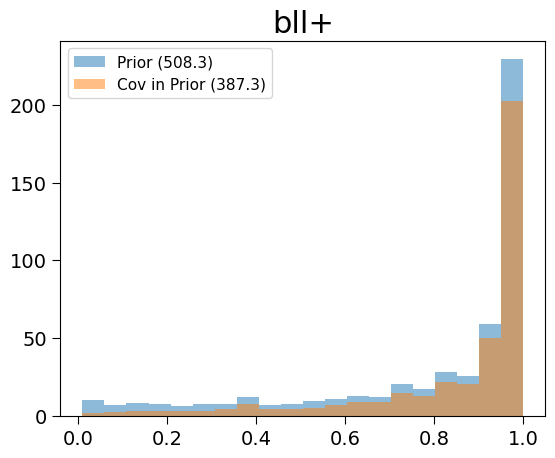

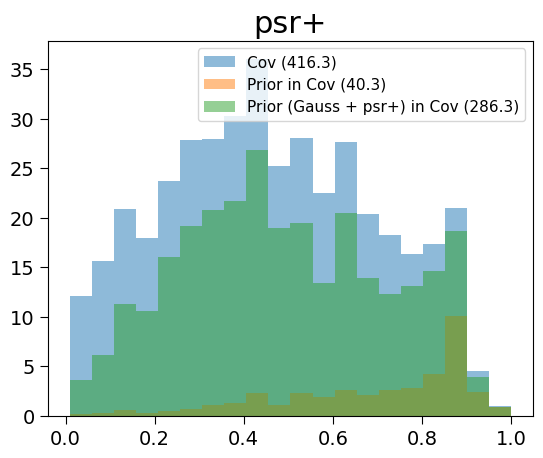

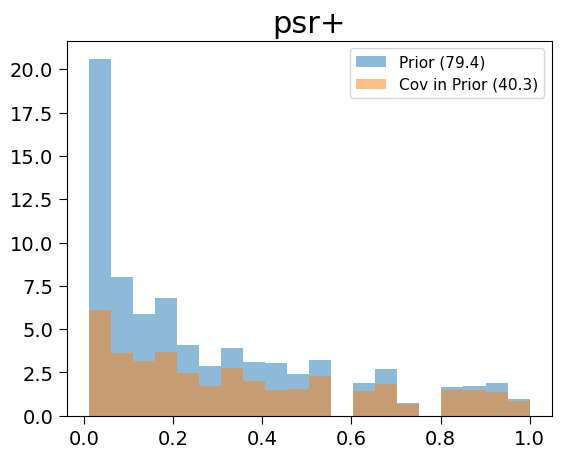

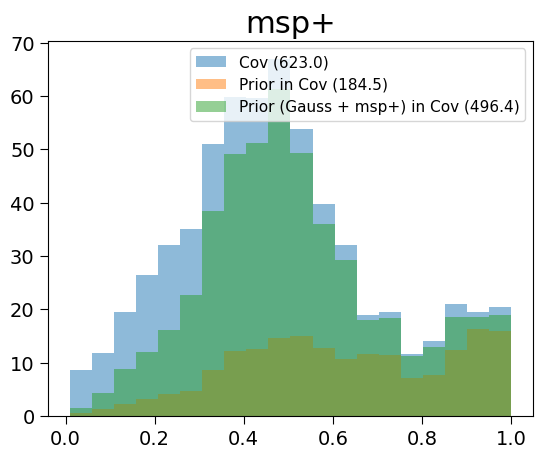

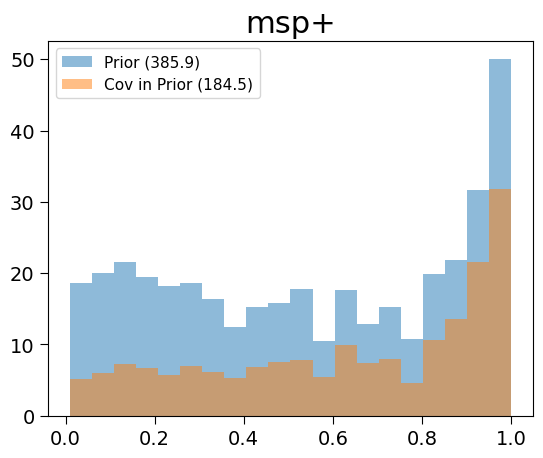

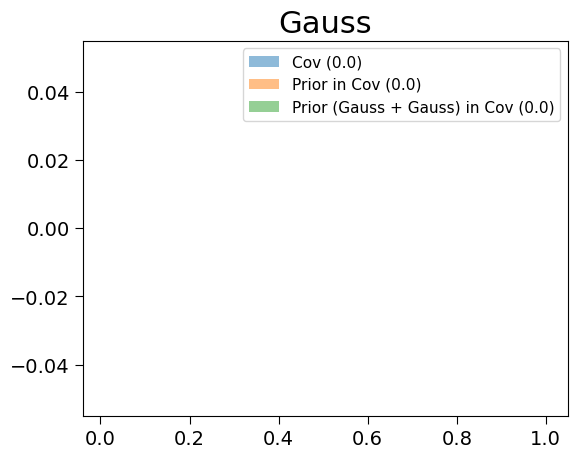

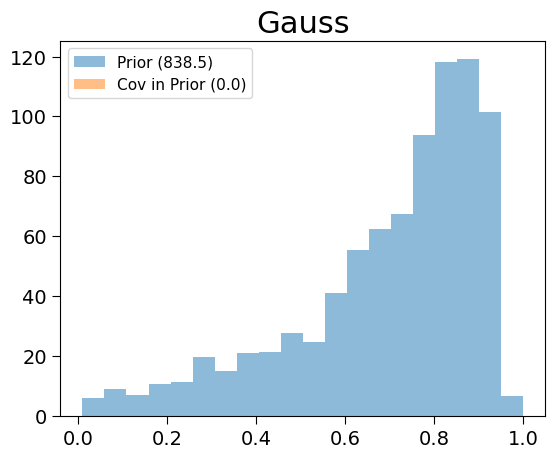

In [154]:
plot_std = 0
threshold = 0.3
gtest1 = None
gtest2 = 'Gauss' #'msp+' # Gauss
if gtest1 is not None:
    ind1 = sum_df1['Group'].loc[gtest1]
    clm1 = '%i_%s' % (ind1, alg1)
    ptest1 = cat_df1[clm1][sources]
else:
    ptest1 = None

if gtest2 is not None:
    if gtest2 == 'Gauss':
        clm2 = 'Gauss_%s' % alg2
    else:
        ind2 = sum_df2['Group'].loc[gtest2]
        clm2 = '%i_%s' % (ind2, alg2)
    ptest2 = cat_df2[clm2][sources]
else:
    ptest2 = None

bins_diff = np.linspace(-1, 1, 21)
bins = np.linspace(0.01, 1, 21)
groups1 = []
groups2 = []
for cl in sum_df2.index:
    print(cl)
    if cl != 'Gauss':
        ind1 = int(sum_df1['Group'].loc[cl])
        clm1 = '%i_%s' % (ind1, alg1)
        probs1 = cat_df1[clm1][sources]
        stds = cat_df1[clm1 + '_std'][sources]
        groups1.append('%i' % ind1)
    else:
        probs1 = np.zeros(len(sources))
        stds = np.ones(len(sources))
    
    if cl == 'Gauss':
        clm2 = '%s_%s' % (cl, alg2)
        groups2.append(cl)
    else:
        ind2 = int(sum_df2['Group'].loc[cl])
        clm2 = '%i_%s' % (ind2, alg2)
        groups2.append('%i' % ind2)
    probs2 = cat_df2[clm2][sources]
    if 0:
        pyplot.figure()
        if plot_std:
            diff = (probs1 - probs2) / (stds + 0.01)
            label = '(%s - %s) / std cov' % (cat1, cat2)
        else:
            #mask = np.array(np.heaviside(probs1 - threshold, 0) * np.heaviside(probs2 - threshold, 0), dtype=bool)
            mask = np.array(np.heaviside(probs1 - threshold, 0), dtype=bool)
            diff = (probs1 - probs2)
            label = '%s - %s' % (cat1, cat2)
        pyplot.hist(diff[mask], bins=bins_diff, alpha=1., label=label)
        pyplot.title(cl)
        pyplot.legend()
    if 1:
        pyplot.figure()
        w = probs1
        pyplot.hist(probs1, bins=bins, weights=w, alpha=0.5, label='%s (%.1f)' % (cat1, sum(w)))
        w = probs1 * probs2
        pyplot.hist(probs1, bins=bins, weights=w, alpha=0.5, label='%s in %s (%.1f)' % (cat2, cat1, sum(w)))
        if 1:
            if ptest2 is not None:
                if 1:
                    w = probs1 * (ptest2 + probs2)
                    label = '%s (%s + %s) in %s (%.1f)' % (cat2, gtest2, cl, cat1, sum(w))
                else:
                    w = probs1 * (ptest2)
                    label = '%s %s in %s (%.1f)' % (cat2, gtest2, cat1, sum(w))
                    
                pyplot.hist(probs1, bins=bins, weights=w, alpha=0.5, label=label)
        pyplot.title(cl)
        pyplot.legend()

        pyplot.figure()
        w = probs2
        pyplot.hist(probs2, bins=bins, weights=w, alpha=0.5, label='%s (%.1f)' % (cat2, sum(w)))
        w = probs2 * probs1
        pyplot.hist(probs2, bins=bins, weights=w, alpha=0.5, label='%s in %s (%.1f)' % (cat1, cat2, sum(w)))
        if 1:
            if ptest1 is not None:
                w = probs2 * ptest1
                label='%s %s in %s (%.1f)' % (cat1, gtest1, cat2, sum(w))
                pyplot.hist(probs2, bins=bins, weights=w, alpha=0.5, label=label)
    
        pyplot.title(cl)
        pyplot.legend()

In [155]:
cat_df2

,log10(Energy_Flux100),LP_beta,log10(LP_EPeak),GLON,GLAT,Signif_Avg,CLASS1,1_PDF,2_PDF,3_PDF,4_PDF,Gauss_PDF
4FGL J0000.3-7355,-11.760649,0.109999,0.030076,307.708984,-42.729538,8.492646,unas,0.168348,0.575888,0.009225,0.119563,0.126976
4FGL J0000.5+0743,-11.714305,0.109660,-0.349232,101.656479,-53.029457,5.681097,unas,0.189166,0.350479,0.010228,0.129620,0.320507
4FGL J0000.7+2530,-12.094175,0.251122,0.948690,108.775070,-35.959175,4.197268,unas,0.029941,0.968732,0.000384,0.000939,0.000004
4FGL J0001.2+4741,-11.863557,0.049796,0.009480,114.250198,-14.338059,5.523873,bcu,0.080707,0.832919,0.002997,0.043842,0.039535
4FGL J0001.2-0747,-11.107484,0.037899,0.014316,89.032722,-67.305008,24.497219,bll,0.073356,0.236130,0.103158,0.071738,0.515618
...,...,...,...,...,...,...,...,...,...,...,...,...
4FGL J2359.3+2502,-11.877070,0.135214,0.473850,108.247383,-36.340054,5.558664,unas,0.115943,0.854659,0.006659,0.018670,0.004069
4FGL J2359.3+1444,-11.627869,0.222978,-0.689550,104.564713,-46.256252,7.791155,unas,0.266414,0.031424,0.007959,0.064871,0.629332
4FGL J2359.7-5041,-11.952324,0.446554,-0.455627,322.128052,-64.472755,5.150436,bcu,0.061082,0.015336,0.003073,0.274645,0.645864
4FGL J2359.9-3736,-11.756382,0.185941,0.285051,345.662842,-74.919624,11.475555,bcu,0.157764,0.661594,0.005711,0.124845,0.050086


In [198]:
flabel_dict = {'log10(Energy_Flux100)': 'log10(Energy_Flux100)' + r' $\rm [erg\,s^{-1}\,cm^{-2}]$', 
               'log10(LP_EPeak)': 'log10(LP_EPeak) [GeV]' }

fname = 'GLAT' # 'LP_beta', 'log10(LP_EPeak)', 'GLAT'
if fname == 'log10(LP_EPeak)':
    fbins = np.arange(-2, 2.01, 0.2)
    if 0:
        fmin = -1.5
        fmax = 1.
    else:
        fmin = np.log10(0.15)
        fmax = np.log10(1.5)
    print(fmin)
elif fname == 'LP_beta':
    fbins = np.arange(0., 0.81, 0.05) #np.linspace(0, 0.6, 11)
    fmin = 0.1
    fmax = 0.5
elif fname == 'GLAT':
    eps = 1.e-15
    fmin = -1.
    fmax = 1.
    GLAT_med_deg = 11.
    GLAT_med = np.deg2rad(GLAT_med_deg)
    GLAT_max_deg = 31.
    GLAT_max = np.deg2rad(GLAT_max_deg)
    dLat = 1.
    issinb = True
    if issinb:
        dsin = np.sin(np.deg2rad(dLat))
        if 0:
            sin_bins0 = np.arange(0, np.sin(GLAT_med), dsin) # equal spacing in sin
            sin_bins1 = np.arange(sin_bins0[-1], np.sin(GLAT_max), 2. * dsin) # equal spacing in sin
            sin_bins0 = np.append(sin_bins0, sin_bins1[1:])
        else:
            sin_bins0 = np.arange(0, np.sin(GLAT_max), dsin) # equal spacing in sin
        sin_bins = np.zeros(2 * len(sin_bins0) - 1)
        sin_bins[:len(sin_bins0)] = -sin_bins0[::-1]
        sin_bins[len(sin_bins0)-1:] = sin_bins0
        fbins = np.rad2deg(np.arcsin(sin_bins)) # transform to angles
    else:
        #db0 = np.arange(0, 9.9, 1.)
        #db0 = np.append(db0, np.arange(10., 30.1, 2.))
        #falpha = 1.1
        falpha = 1.
        db0 = np.arange(0., 30.1, 1.)**falpha
        msk = db0 < 30.1
        db0 = db0[msk]
        fbins = np.append(-db0[::-1], db0[1:])
    print(fbins)
    
    #fbins = np.arange(-GLAT_max_deg, GLAT_max_deg, dLat - eps)
    
fbinsc = (fbins[1:] + fbins[:-1]) / 2.
if fname == 'GLAT':
    dfbins = (fbins[1:] - fbins[:-1]) / np.cos(np.deg2rad(fbinsc))
    print(dfbins)
    
vals = cat_df2[fname]

if fmin is not None:
    smask = (fbinsc < fmin) | (fbinsc > fmax)
else:
    smask = np.ones_like(fbinsc, dtype=bool)

if fname == 'GLAT':
    ymax = 200
    ymin = -20
elif llat:
    ymax = 300
    ymin = -50
    #smask = (fbinsc < fmin) | (fbinsc > fmax)
else:
    ymax = 350
    ymin = -50
    #smask = (fbinsc < fmin) | (fbinsc > fmax)

ncol = 2
if fname == 'LP_beta':
    ymax = 200
    ymin = -20
    #ncol = 2
    #smask = (fbinsc < fmin)
    
h1s = {}
h2s = {}
#fbins = 20

# distributions of unassociated sources
for cl in sum_df2.index:
    print(cl)
    if cl != 'Gauss':
        ind1 = int(sum_df1['Group'].loc[cl])
        clm1 = '%i_%s' % (ind1, alg1)
        probs1 = cat_df1[clm1][sources]
    else:
        probs1 = np.zeros(len(sources))
        stds = np.ones(len(sources))
    
    if cl == 'Gauss':
        clm2 = '%s_%s' % (cl, alg2)
    else:
        ind2 = int(sum_df2['Group'].loc[cl])
        clm2 = '%i_%s' % (ind2, alg2)
    probs2 = cat_df2[clm2][sources]
    
    
    w = probs1
    h1s[cl] = np.histogram(vals[sources], bins=fbins, weights=w)[0]
    w = probs2
    h2s[cl] = np.histogram(vals[sources], bins=fbins, weights=w)[0]
    if fname == 'GLAT':
        h1s[cl] /= dfbins
    
h2s['unas'] = 1. * np.histogram(vals[sources], bins=fbins)[0]
h2s['assoc'] = 1. * np.histogram(vals[asources], bins=fbins)[0]

if fname == 'GLAT':
    h2s['unas'] /= dfbins
    h2s['assoc'] /= dfbins

# distributions of associated sources
print('Distribution of %s for associated sources' % fname)
ah1s = {}
ah2s = {}
for cl in sum_df1.index:
    cls = sum_df1['Physical classes'].loc[cl].split(', ')
    cls_mask1 = util.get_cl_mask(cls, cat_df1, cname=class_name)
    cls_mask2 = util.get_cl_mask(cls, cat_df2, cname=class_name)
    ah1s[cl] = 1. * np.histogram(vals[cls_mask1], bins=fbins, weights=None)[0]
    print('%s: %.3f +- %.3f' % (cl, np.mean(vals[cls_mask1]), np.std(vals[cls_mask1])/np.sqrt(sum(cls_mask1))))
    ah2s[cl] = 1. *np.histogram(vals[cls_mask2], bins=fbins, weights=None)[0]
    if fname == 'GLAT':
        ah1s[cl] /= dfbins
        ah2s[cl] /= dfbins

nGauss = sum(h2s['Gauss'])
fGauss = (sum(h2s['Gauss']) / len(sources))


[-30.40571455 -29.25302992 -28.11319205 -26.98534386 -25.86869079
 -24.76249374 -23.66606301 -22.57875297 -21.49995741 -20.42910547
 -19.36565799 -18.30910431 -17.25895944 -16.21476146 -15.17606923
 -14.14246032 -13.11352911 -12.0888851  -11.0681513  -10.05096279
  -9.03696544  -8.02581458  -7.01717391  -6.0107144   -5.00611323
  -4.00305283  -3.00121996  -2.00030478  -1.           0.
   1.           2.00030478   3.00121996   4.00305283   5.00611323
   6.0107144    7.01717391   8.02581458   9.03696544  10.05096279
  11.0681513   12.0888851   13.11352911  14.14246032  15.17606923
  16.21476146  17.25895944  18.30910431  19.36565799  20.42910547
  21.49995741  22.57875297  23.66606301  24.76249374  25.86869079
  26.98534386  28.11319205  29.25302992  30.40571455]
[1.32872689 1.29927491 1.27208558 1.24695766 1.22371503 1.20220304
 1.18228541 1.16384175 1.14676541 1.13096174 1.11634653 1.1028448
 1.0903897  1.07892155 1.06838713 1.05873895 1.04993466 1.04193662
 1.03471139 1.02822942 1.022

In [200]:
sum_df2

,Group,Node,Physical classes,N assoc,PDF assoc,"PDF unas,unk,bcu,spp"
Class label,,,,,,
fsrq+,1,000,"fsrq, nlsy1, css",833,573.8,692.2
bll+,2,001,"bll, sey, sbg, agn, ssrq, rdg",1565,868.3,1068.6
psr+,3,010,"snr, hmb, nov, pwn, psr, gc",225,262.1,120.3
msp+,4,011,"msp, lmb, glc, gal, sfr, bin",244,177.1,511.6
Gauss,5,NaN,Gauss,0.0,429.6,1155.3


In [201]:
ah1s['psr+']

array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.92685145,  0.        ,
        1.88903979,  1.90488044,  0.        ,  0.96645307,  1.9450912 ,
        2.93408662,  1.96580578,  0.        ,  0.        ,  1.98773883,
        2.98891926,  4.99067086, 16.98899544, 47.99817231, 31.99878154,
        7.99482138,  4.99067086,  2.98891926,  3.97547767,  0.99082316,
        0.98716765,  0.        ,  0.97802887,  1.9450912 ,  2.8993592 ,
        0.95975127,  0.95244022,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.88420321,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ])

save figure to file: ../../plots/SGU/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_unas_unk//prior_vs_cov_unas_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_unas_unk.pdf


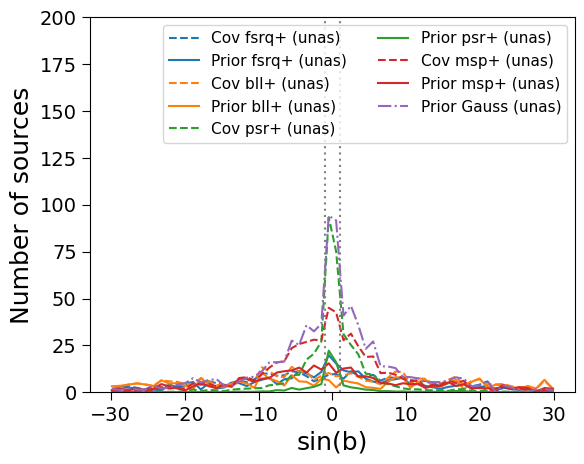

In [202]:

# plot distributions of features
fig_width = 6.3  # width in inches
fig_height = 5    # height in inches
pars_dict = {'fig_size': [fig_width, fig_height], 
             'left': 0.18,
             'font.size': 12,
            'legend.fontsize': 11,}

putil.setup_figure_pars(pars_dict)
lss = ['-', '--', '-.', ':']
alpha = 1

pyplot.figure()
for i, cl in enumerate(sum_df2.index):
    if cl != 'Gauss':
        node = sum_df2['Node'].iloc[i]
        ls2 = '-'
    else:
        node = cl
        ls2 = '-.'
    color = mdl_style_dict[node]['color']
    if cl in sum_df1.index:
        ln = pyplot.plot(fbinsc, h1s[cl], alpha=alpha, ls='--', 
                         c=color, label='%s %s (unas)' % (cat1, cl))
    pyplot.plot(fbinsc, h2s[cl], alpha=alpha, ls=ls2, color=color,
                     label='%s %s (unas)' % (cat2, cl))

if fmin is not None:
    color = mdl_style_dict['vertical']['color']
    ls = mdl_style_dict['vertical']['ls']
    pyplot.plot([fmin, fmin], [0, ymax], ls=ls, color=color)
    pyplot.plot([fmax, fmax], [0, ymax], ls=ls, color=color)

pyplot.legend(ncol=ncol)
if fname == 'GLAT' and issinb:
    pyplot.xlabel('sin(b)')
else:
    pyplot.xlabel(flabel_dict.get(fname, fname))
pyplot.ylim(0, ymax)
pyplot.ylabel('Number of sources')
#pyplot.grid()

if save_plots:
    fn = '%s/prior_vs_cov_unas_%s.pdf' % (plots_folder, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


In [203]:
h2s

{'fsrq+': array([ 0.98049643,  3.24390304,  2.42704793,  2.05460431,  1.15586396,
         1.36993868,  1.13533499,  3.70790255,  2.83381673,  3.57401974,
         5.35485686,  1.47702523,  4.92320425,  2.06811662,  2.48383054,
         4.89993066,  4.85274319,  3.26324807,  5.40943266,  6.66054781,
         7.80948423,  4.3286164 ,  6.91946303,  7.43476943, 11.36360997,
        10.01096073,  7.92918131, 10.83983026, 19.81234722, 15.30182355,
        11.65532398, 10.67005303, 11.15486743,  7.22357203,  5.71329368,
         4.78877816,  6.40201999,  6.95656719,  7.74959329,  4.06275445,
         4.46055859,  3.40219649,  2.60704214,  1.88904812,  2.86983801,
         3.45890157,  4.42494669,  1.82143021,  2.84089888,  3.29006689,
         0.68928815,  2.49524609,  1.56336647,  1.4391909 ,  1.74286083,
         0.14750273,  1.56777355,  0.6213451 ]),
 'bll+': array([ 3.17314124,  3.44952628,  4.05735864,  4.78902129,  4.10642415,
         3.29472678,  6.36887952,  4.56510486,  4.9633222 

In [204]:
fbins[-1]**(1/falpha), 22**falpha

(22.291592922373567, 29.968496064182354)

save figure to file: ../../plots/SGU/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_unas_unk//prior_models_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_unas_unk_GLAT_sinb.pdf


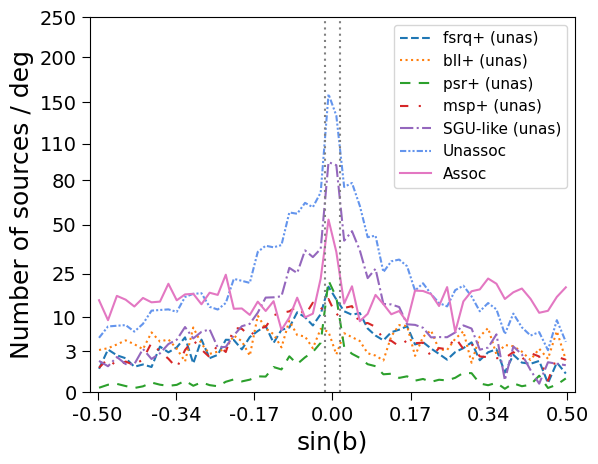

In [205]:

# plot distributions of features
fig_width = 6.3  # width in inches
fig_height = 5    # height in inches
pars_dict = {'fig_size': [fig_width, fig_height], 
             'left': 0.18,
             'font.size': 12,
            'legend.fontsize': 11,}

putil.setup_figure_pars(pars_dict)
lss = ['-', '--', '-.', ':']
alpha = 1

if fname == 'GLAT':
    scale_func = lambda x: np.sign(x) * np.sqrt(np.abs(x))
    scale_func_inv = lambda x: x**2
else:
    scale_func = lambda x: x
    scale_func_inv = lambda x: x
    
pyplot.figure()
ax = pyplot.subplot(1, 1, 1)
for i, cl in enumerate(sum_df2.index):
    if cl != 'Gauss':
        node = sum_df2['Node'].iloc[i]
        label='%s (unas)' % (cl)
    else:
        node = cl
        label='SGU-like (unas)'
    color = mdl_style_dict[node]['color']
    ls = mdl_style_dict[node]['ls']
    pyplot.plot(fbinsc, scale_func(h2s[cl]), alpha=alpha, ls=ls, color=color, label=label)

color = mdl_style_dict['unassoc']['color']
ls = mdl_style_dict['unassoc']['ls']
pyplot.plot(fbinsc, scale_func(h2s['unas']), alpha=alpha, ls=ls, color=color, label='Unassoc')

color = mdl_style_dict['assoc']['color']
ls = mdl_style_dict['assoc']['ls']
if fname == 'GLAT':
    pyplot.plot(fbinsc, scale_func(h2s['assoc']), alpha=alpha, ls=ls, color=color, label='Assoc')
else:
    scaling = len(sources) / len(asources)
    pyplot.plot(fbinsc, scale_func(scaling * h2s['assoc']), alpha=alpha, ls=ls, color=color, 
                     label='Assoc (x%.1f)' % scaling)

ymax_loc = 250

if fname == 'GLAT':
    color = mdl_style_dict['vertical']['color']
    ls = mdl_style_dict['vertical']['ls']
    pyplot.plot([fmin, fmin], [0, ymax_loc], ls=ls, color=color)
    pyplot.plot([fmax, fmax], [0, ymax_loc], ls=ls, color=color)
    #pyplot.title('Prior shift model')

if llat:
    plot_text = r'$|b| < %i^\circ$' % bmask + '\n'
    plot_text += r'#SGU-like = %i (%i%%)' % (nGauss, fGauss * 100)
    ax.text(0.99, 0.5, plot_text, #fontsize=10, 
            transform=ax.transAxes,
            horizontalalignment='right', verticalalignment='top')


pyplot.legend(ncol=1)

pyplot.ylim(0, scale_func(ymax_loc))
if fname == 'GLAT' and issinb:
    pyplot.xlabel('sin(b)')
else:
    pyplot.xlabel(flabel_dict.get(fname, fname))

if fname == 'GLAT':
    pyplot.ylabel('Number of sources / deg')
    glat_yticks = np.array([0, 3, 10, 25, 50, 80, 110, 150, 200, 250])
    ax.set_yticks(scale_func(glat_yticks))
    ax.set_yticklabels(glat_yticks)
    pyplot.xlim(-GLAT_max_deg, GLAT_max_deg)
    if issinb:
        xticks = np.arange(-30., 31, 10) #ax.get_xticks()
        ax.set_xticks(xticks)
        xtick_labels = ['%.2f' %x for x in np.sin(np.deg2rad(xticks))]
        ax.set_xticklabels(xtick_labels)
        if 0:
            ax_twin = ax.twiny()
            xlims = ax.get_xlim()
            ax_twin.set_xlim(xlims)
            ax_twin.set_xticks(xticks)
            ax_twin.set_xlabel('GLAT')
        fname_extra = '_sinb'
    else:
        fname_extra = '_falpha%.1f' % falpha
else:
    pyplot.ylabel('Number of sources')
    fname_extra = ''
#pyplot.yscale('asinh')
#pyplot.grid()

save_plots = 1
if save_plots:
    fn = '%s/prior_models_%s_%s%s.pdf' % (plots_folder, descr_str, fname, fname_extra)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


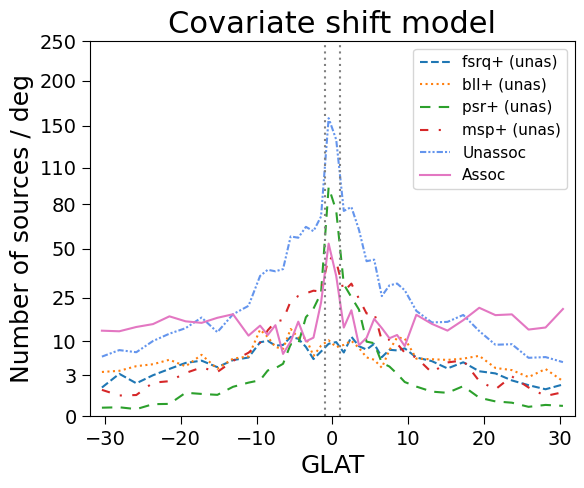

In [173]:

# plot distributions of features
fig_width = 6.3  # width in inches
fig_height = 5    # height in inches
pars_dict = {'fig_size': [fig_width, fig_height], 
             'left': 0.18,
             'font.size': 12,
            'legend.fontsize': 11,}

putil.setup_figure_pars(pars_dict)
lss = ['-', '--', '-.', ':']
alpha = 1

pyplot.figure()
ax = pyplot.subplot(1, 1, 1)
for i, cl in enumerate(sum_df1.index):
    node = sum_df2['Node'].iloc[i]
    label='%s (unas)' % (cl)
    color = mdl_style_dict[node]['color']
    ls = mdl_style_dict[node]['ls']
    pyplot.plot(fbinsc, scale_func(h1s[cl]), alpha=alpha, ls=ls, color=color, label=label)

color = mdl_style_dict['unassoc']['color']
ls = mdl_style_dict['unassoc']['ls']
pyplot.plot(fbinsc, scale_func(h2s['unas']), alpha=alpha, ls=ls, color=color, label='Unassoc')

color = mdl_style_dict['assoc']['color']
ls = mdl_style_dict['assoc']['ls']
if fname == 'GLAT':
    pyplot.plot(fbinsc, scale_func(h2s['assoc']), alpha=alpha, ls=ls, color=color, label='Assoc')
else:
    scaling = len(sources) / len(asources)
    pyplot.plot(fbinsc, scale_func(scaling * h2s['assoc']), alpha=alpha, ls=ls, color=color, label='Assoc (x%.1f)' % scaling)

ymax_loc = 250

if fname == 'GLAT':
    color = mdl_style_dict['vertical']['color']
    ls = mdl_style_dict['vertical']['ls']
    pyplot.plot([fmin, fmin], [0, ymax_loc], ls=ls, color=color)
    pyplot.plot([fmax, fmax], [0, ymax_loc], ls=ls, color=color)
pyplot.title('Covariate shift model')

if llat:
    plot_text = r'$|b| < %i^\circ$' % bmask + '\n'
    plot_text += r'#SGU-like = %i (%i%%)' % (nGauss, fGauss * 100)
    ax.text(0.99, 0.5, plot_text, #fontsize=10, 
            transform=ax.transAxes,
            horizontalalignment='right', verticalalignment='top')


pyplot.legend(ncol=1)
pyplot.xlabel(flabel_dict.get(fname, fname))
pyplot.ylim(0, scale_func(ymax_loc))

if fname == 'GLAT':
    pyplot.ylabel('Number of sources / deg')
    ax.set_yticks(scale_func(glat_yticks))
    ax.set_yticklabels(glat_yticks)
    pyplot.xlim(-GLAT_max_deg, GLAT_max_deg)
else:
    pyplot.ylabel('Number of sources')
#pyplot.grid()

if save_plots:
    fn = '%s/cov_models_%s_%s.pdf' % (plots_folder, descr_str, fname)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


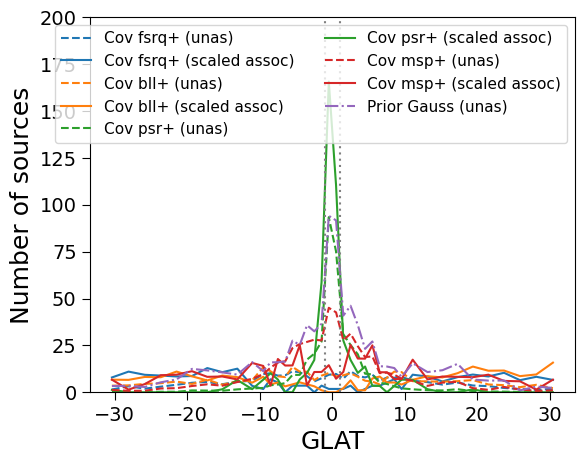

In [174]:
# comparison of distributions for cov shift model
pyplot.figure()
for i, cl in enumerate(sum_df1.index):
    node = sum_df2['Node'].iloc[i]
    color = mdl_style_dict[node]['color']
    ln = pyplot.plot(fbinsc, h1s[cl], alpha=alpha, c=color, ls='--', label='%s %s (unas)' % (cat1, cl))[0]
    #color = ln.get_color()
    #pyplot.plot(fbinsc, h2s[cl], alpha=alpha, c=color, ls='-.', label='%s %s unas' % (cat2, cl))[0]
    scaling = sum(h1s[cl][smask]) / sum(ah1s[cl][smask])
    pyplot.plot(fbinsc, scaling * ah1s[cl], alpha=alpha, c=color, ls='-', label='%s %s (scaled assoc)' % (cat1, cl))
cl = 'Gauss'
color = mdl_style_dict[cl]['color']
pyplot.plot(fbinsc, h2s[cl], alpha=alpha, c=color, ls='-.', label='%s %s (unas)' % (cat2, cl))[0]

if fmin is not None:
    color = mdl_style_dict['vertical']['color']
    ls = mdl_style_dict['vertical']['ls']
    pyplot.plot([fmin, fmin], [0, ymax_loc], ls=ls, color=color)
    pyplot.plot([fmax, fmax], [0, ymax_loc], ls=ls, color=color)

pyplot.legend(ncol=ncol)
#pyplot.xlim(-2, 2)
pyplot.ylim(0, ymax)
#pyplot.grid()
pyplot.xlabel(flabel_dict.get(fname, fname))
pyplot.ylabel('Number of sources')

if save_plots:
    fn = '%s/cov_unas_vs_assoc_%s.pdf' % (plots_folder, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


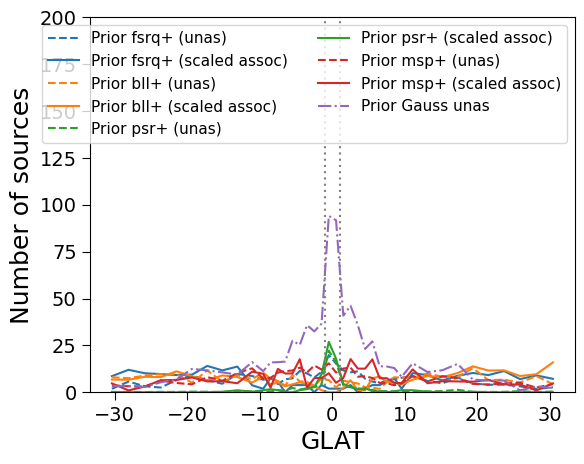

In [175]:
# comparison of distributions for prior shift model
pyplot.figure()
for i, cl in enumerate(sum_df1.index):
    node = sum_df2['Node'].iloc[i]
    color = mdl_style_dict[node]['color']
    pyplot.plot(fbinsc, h2s[cl], alpha=alpha, ls='--', label='%s %s (unas)' % (cat2, cl))
    #pyplot.plot(fbinsc, h2s[cl], alpha=alpha, c=color, ls='-.', label='%s %s unas' % (cat2, cl))[0]
    scaling = sum(h2s[cl][smask]) / sum(ah2s[cl][smask])
    pyplot.plot(fbinsc, scaling * ah2s[cl], alpha=alpha, c=color, ls='-', label='%s %s (scaled assoc)' % (cat2, cl))
cl = 'Gauss'
color = mdl_style_dict[cl]['color']
pyplot.plot(fbinsc, h2s[cl], alpha=alpha, c=color, ls='-.', label='%s %s unas' % (cat2, cl))[0]
if fmin is not None:
    color = mdl_style_dict['vertical']['color']
    ls = mdl_style_dict['vertical']['ls']
    pyplot.plot([fmin, fmin], [0, ymax_loc], ls=ls, color=color)
    pyplot.plot([fmax, fmax], [0, ymax_loc], ls=ls, color=color)

pyplot.legend(ncol=ncol)
#pyplot.xlim(-2, 2)
pyplot.ylim(0, ymax)
#pyplot.grid()
pyplot.xlabel(flabel_dict.get(fname, fname))
pyplot.ylabel('Number of sources')

if save_plots:
    fn = '%s/prior_unas_vs_assoc_%s.pdf' % (plots_folder, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


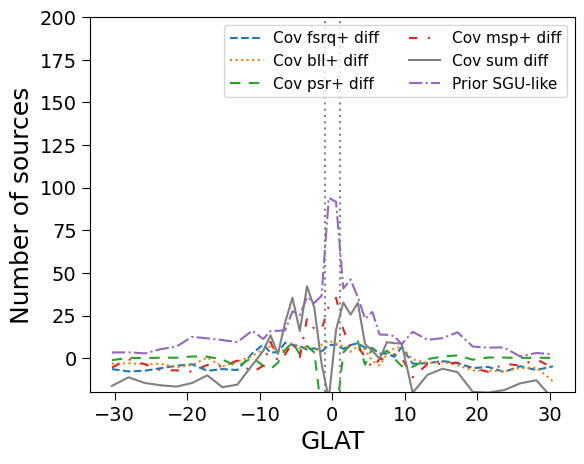

In [176]:
# excess difference
tot = 0.
pyplot.figure()
ax = pyplot.subplot(1, 1, 1)
for i, cl in enumerate(sum_df1.index):
    node = sum_df2['Node'].iloc[i]
    color = mdl_style_dict[node]['color']
    ls = mdl_style_dict[node]['ls']
    scaling = sum(h1s[cl][smask]) / sum(ah1s[cl][smask])
    ys = h1s[cl] - scaling * ah1s[cl]
    tot += (ys)
    pyplot.plot(fbinsc, ys, alpha=alpha, ls=ls, c=color, label='%s %s diff' % (cat1, cl))[0]
pyplot.plot(fbinsc, tot, alpha=alpha, ls='-', c='grey', label='%s sum diff' % (cat1))[0]

cl = 'Gauss'
color = mdl_style_dict[cl]['color']
ls = mdl_style_dict[cl]['ls']
pyplot.plot(fbinsc, h2s[cl], alpha=alpha, c=color, ls=ls, label='%s SGU-like' % (cat2))[0]
if fmin is not None:
    color = mdl_style_dict['vertical']['color']
    ls = mdl_style_dict['vertical']['ls']
    pyplot.plot([fmin, fmin], [ymin, ymax_loc], ls=ls, color=color)
    pyplot.plot([fmax, fmax], [ymin, ymax_loc], ls=ls, color=color)

pyplot.legend(ncol=ncol)
#pyplot.xlim(-2, 2)
pyplot.ylim(ymin, ymax)
#pyplot.grid()
pyplot.xlabel(flabel_dict.get(fname, fname))
pyplot.ylabel('Number of sources')

if llat:
    plot_text = r'$|b| < %i^\circ$' % bmask + '\n'
    plot_text += r'#SGU-like = %i (%i%%)' % (nGauss, fGauss * 100)
    ax.text(0.99, 0.7, plot_text, #fontsize=10, 
            transform=ax.transAxes,
            horizontalalignment='right', verticalalignment='top')


if save_plots:
    fn = '%s/cov_excess_and_Gauss_%s_%s.pdf' % (plots_folder, descr_str, fname)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


In [167]:
# compare the total number in the Gaussian component and in the cov shift difference
print('Cov difference in Gauss range: %.1f' % sum(tot[~smask]))
print('Number of Gauss sources: %.1f' % sum(h2s['Gauss'][~smask]))
print('Total number of Gauss sources: %.1f' % sum(h2s['Gauss']))
print('Fraction of Gauss sources: %.4f' % (sum(h2s['Gauss']) / len(sources)))

Cov difference in Gauss range: 574.5
Number of Gauss sources: 583.8
Total number of Gauss sources: 624.0
Fraction of Gauss sources: 0.5310


In [168]:
len(sources)

1175

In [169]:
prob_mat1 = np.array([cat_df1['%s_%s' % (gr, alg1)][sources] for gr in groups1]).T
prob_mat2 = np.array([cat_df2['%s_%s' % (gr, alg2)][sources] for gr in groups2])
cm = np.dot(prob_mat2, prob_mat1)
prob_mat2.shape, prob_mat1.shape, groups1, groups2

((5, 1175), (1175, 4), ['1', '2', '3', '4'], ['1', '2', '3', '4', 'Gauss'])

In [170]:
plot_confusion = False
if plot_confusion:
    fig_width = 6.3  # width in inches
    fig_height = 5    # height in inches
    pars_dict = {'fig_size': [fig_width, fig_height], 
                 'left': 0.18,
                 'font.size': 12}

    putil.setup_figure_pars(pars_dict)
    normalize = None
    fig, ax = pyplot.subplots()
    if normalize is None:
        seaborn.heatmap(cm, annot=True, cmap='viridis', fmt='.1f')
    else:
        seaborn.heatmap(cm, annot=True, cmap='viridis', fmt='.2f')
    ax.set_xticklabels(sum_df1.index)
    ax.set_yticklabels(sum_df2.index, rotation=0)
    pyplot.xlabel(cat1 + ' shift model')
    pyplot.ylabel(cat2 + ' shift model')

    if save_plots:
        fn = '%s/prior_vs_cov_confusion_%s.pdf' % (plots_folder, descr_str)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if save_png:
            fn = fn.replace('.pdf', '.png')
            pyplot.savefig(fn, metadata=fig_meta)


In [171]:
sum_df1

,Group,Node,Physical classes,N assoc,RF assoc,NN assoc,"RF unas,unk,bcu,spp","NN unas,unk,bcu,spp"
Class label,,,,,,,,
fsrq+,1,000,"fsrq, nlsy1, css",833,835.2 +- 24.4,832.9 +- 40.6,1156.1 +- 28.3,1276.2 +- 84.2
bll+,2,001,"bll, sey, sbg, agn, ssrq, rdg",1565,1568.0 +- 31.1,1560.5 +- 43.2,1791.7 +- 35.1,1801.1 +- 66.4
psr+,3,010,"snr, hmb, nov, pwn, psr, gc",225,214.5 +- 18.8,227.8 +- 36.6,576.8 +- 43.4,494.1 +- 97.2
msp+,4,011,"msp, lmb, glc, gal, sfr, bin",244,249.0 +- 17.7,245.5 +- 26.2,799.3 +- 39.1,752.5 +- 64.4


In [172]:
sum_df2

,Group,Node,Physical classes,N assoc,PDF assoc,"PDF unas,unk,bcu,spp"
Class label,,,,,,
fsrq+,1,000,"fsrq, nlsy1, css",833,573.8,692.2
bll+,2,001,"bll, sey, sbg, agn, ssrq, rdg",1565,868.3,1068.6
psr+,3,010,"snr, hmb, nov, pwn, psr, gc",225,262.1,120.3
msp+,4,011,"msp, lmb, glc, gal, sfr, bin",244,177.1,511.6
Gauss,5,NaN,Gauss,0.0,429.6,1155.3
